
# Lorenz–63: Choosing the Largest Stable `dt` (No Loss of Representation)

This notebook sweeps candidate time steps `dt` for integrating the Lorenz–63 system and selects the **largest** `dt` that preserves key properties relative to a high‑accuracy reference:
- **Numerical fidelity** (NRMSE vs. reference)
- **Distributional fidelity** (histogram JS divergence)
- **Temporal structure** (autocorrelation at lag 1 and integrated ACF)
- **Spectral structure** (PSD similarity, dominant peak location)
- **Tail behavior** (95th/99th quantiles, KS D in the upper tail)
- **Largest Lyapunov exponent** (via two‑trajectory divergence)

You can tune thresholds in the config cell below.


In [20]:

import numpy as np
import math
import matplotlib.pyplot as plt

# Optional, used for tabular summary
try:
    import pandas as pd
except Exception:
    pd = None

# ----------------------------
# Configuration (edit me)
# ----------------------------
SEED = 42
np.random.seed(SEED)

# Reference integrator step (small) and total simulated time
DT_REF = 1e-3       # small reference step
TOTAL_TIME = 100.0  # seconds of simulated time (increase for more stable stats)
WARMUP_TIME = 10.0  # discard initial transient

# Observation sampling interval for comparisons/plots
DT_OBS = 0.02
T_ALIGN = 2.5 

# Candidate integrator steps to test (largest passing one will be chosen)
CANDIDATE_DT = [0.04, 0.02, 0.01, 0.005, 0.0025, 0.001, 0.0005, 0.0001]

# Acceptance thresholds ("no loss of representation")
THRESHOLDS = {
    'nrmse_max'      : 0.05,  # per coordinate NRMSE <= 5%
    'js_hist_max'    : 0.05,  # Jensen-Shannon over histograms
    'acf1_delta_max' : 0.02,  # |rho(1) - rho_ref(1)| <= 0.02
    'tau_rel_max'    : 0.05,  # |tau - tau_ref| / tau_ref <= 5%
    'psd_js_max'     : 0.05,  # JS divergence on normalized PSD
    'peak_rel_max'   : 0.03,  # dominant PSD peak shift <= 3%
    'q95_rel_max'    : 0.05,  # relative error on 95th quantile of |x| <= 5%
    'q99_rel_max'    : 0.05,  # relative error on 99th quantile of |x| <= 5%
    'ks_tail_max'    : 0.10,  # KS D in the upper tail <= 0.10
    'lyap_rel_max'   : 0.10,  # relative error on estimated lambda1 <= 10%
}

# Initial condition
X0 = np.array([1.0, 1.0, 1.0], dtype=float)

# Lorenz-63 parameters
SIGMA = 10.0
RHO   = 28.0
BETA  = 8.0/3.0

print("Configured. Edit DT_REF, DT_OBS, CANDIDATE_DT, and THRESHOLDS as needed.")


Configured. Edit DT_REF, DT_OBS, CANDIDATE_DT, and THRESHOLDS as needed.


In [21]:

def lorenz63_rhs(x):
    # x = [x, y, z]
    dx = SIGMA * (x[1] - x[0])
    dy = x[0] * (RHO - x[2]) - x[1]
    dz = x[0] * x[1] - BETA * x[2]
    return np.array([dx, dy, dz], dtype=float)

def rk4_step(x, dt):
    k1 = lorenz63_rhs(x)
    k2 = lorenz63_rhs(x + 0.5 * dt * k1)
    k3 = lorenz63_rhs(x + 0.5 * dt * k2)
    k4 = lorenz63_rhs(x + dt * k3)
    return x + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)

def integrate_lorenz63(x0, dt, total_time, warmup_time=0.0):
    n_steps = int(total_time / dt)
    n_warm  = int(warmup_time / dt)
    X = np.zeros((n_steps, 3), dtype=float)
    x = x0.copy()
    for i in range(n_steps):
        x = rk4_step(x, dt)
        X[i] = x
    # discard warmup
    if n_warm > 0 and n_warm < len(X):
        X = X[n_warm:]
    return X

def downsample_to_dt_obs(traj, dt_source, dt_obs):
    # keep every q-th sample so that dt_source * q = dt_obs (approximately integer q)
    q = max(1, int(round(dt_obs / dt_source)))
    return traj[::q]


In [22]:

def nrmse(a, b):
    # per-coordinate NRMSE normalized by std of reference
    assert a.shape == b.shape
    out = []
    for j in range(a.shape[1]):
        ref = b[:, j]
        err = a[:, j] - ref
        denom = np.std(ref)
        if denom <= 1e-12:
            out.append(0.0)
        else:
            out.append(np.sqrt(np.mean(err*err)) / denom)
    return np.array(out)

def _js_divergence(p, q, eps=1e-12):
    # Jensen-Shannon divergence for discrete distributions
    p = np.asarray(p, dtype=float)
    q = np.asarray(q, dtype=float)
    p = p / max(eps, p.sum())
    q = q / max(eps, q.sum())
    m = 0.5*(p+q)
    def _kl(a, b):
        mask = (a > eps) & (b > eps)
        return np.sum(a[mask] * (np.log(a[mask]) - np.log(b[mask])))
    return 0.5*_kl(p, m) + 0.5*_kl(q, m)

def histogram_js(traj_a, traj_b, bins=128):
    # average JS over coordinates using shared bin edges per coordinate
    js_vals = []
    for j in range(traj_a.shape[1]):
        x = traj_a[:, j]
        y = traj_b[:, j]
        xmin = min(x.min(), y.min())
        xmax = max(x.max(), y.max())
        edges = np.linspace(xmin, xmax, bins+1)
        pa, _ = np.histogram(x, bins=edges, density=True)
        pb, _ = np.histogram(y, bins=edges, density=True)
        js_vals.append(_js_divergence(pa, pb))
    return float(np.mean(js_vals))

def autocorr(x, max_lag):
    x = np.asarray(x, dtype=float)
    x = x - np.mean(x)
    var = np.var(x)
    if var < 1e-12:
        return np.zeros(max_lag+1)
    # full autocorr via FFT for speed
    n = len(x)
    nfft = 1
    while nfft < 2*n:
        nfft <<= 1
    fx = np.fft.rfft(x, nfft)
    acf = np.fft.irfft(fx * np.conj(fx), nfft)[:n]
    acf = acf / (var * np.arange(n, 0, -1))
    return acf[:max_lag+1]

def acf_metrics(traj_a, traj_b, max_lag=200):
    # returns: mean |delta acf1| over coords, relative delta of integrated acf time
    acf1_diffs = []
    tau_rel_diffs = []
    for j in range(traj_a.shape[1]):
        acf_a = autocorr(traj_a[:, j], max_lag)
        acf_b = autocorr(traj_b[:, j], max_lag)
        # lag-1 difference
        acf1_diffs.append(abs(acf_a[1] - acf_b[1]))
        # integrated time: sum of positive lags until first non-positive
        def tau_int(acf):
            s = 0.0
            for k in range(1, len(acf)):
                if acf[k] <= 0.0:
                    break
                s += acf[k]
            return s
        ta = tau_int(acf_a)
        tb = tau_int(acf_b)
        if tb <= 1e-12:
            tau_rel_diffs.append(0.0)
        else:
            tau_rel_diffs.append(abs(ta - tb) / tb)
    return float(np.mean(acf1_diffs)), float(np.mean(tau_rel_diffs))

def psd_js_and_peak(traj_a, traj_b, dt_obs):
    # normalized one-sided PSD via FFT for the x-coordinate (j=0)
    def psd_1d(x, dt):
        x = x - np.mean(x)
        n = len(x)
        freqs = np.fft.rfftfreq(n, d=dt)
        X = np.fft.rfft(x)
        psd = (np.abs(X)**2) / (n / dt)  # proportional
        psd = psd / max(1e-12, psd.sum())  # normalize
        return freqs, psd

    f_a, P_a = psd_1d(traj_a[:, 0], dt_obs)
    f_b, P_b = psd_1d(traj_b[:, 0], dt_obs)
    # ensure same length by truncation
    m = min(len(P_a), len(P_b))
    js = _js_divergence(P_a[:m], P_b[:m])

    # dominant peak frequency shift
    idx_a = int(np.argmax(P_a))
    idx_b = int(np.argmax(P_b))
    fa = f_a[idx_a] if idx_a < len(f_a) else 0.0
    fb = f_b[idx_b] if idx_b < len(f_b) else 0.0
    denom = max(1e-9, abs(fb))
    peak_rel = abs(fa - fb) / denom
    return float(js), float(peak_rel)

def tail_metrics_absx(traj_a, traj_b):
    # Compare tails on |x| coordinate (j=0)
    ax = np.abs(traj_a[:, 0])
    bx = np.abs(traj_b[:, 0])
    def q(p, v): return np.quantile(v, p)
    q95a, q99a = q(0.95, ax), q(0.99, ax)
    q95b, q99b = q(0.95, bx), q(0.99, bx)
    def relerr(a, b): return 0.0 if abs(b) < 1e-12 else abs(a-b)/abs(b)
    q95_re = relerr(q95a, q95b)
    q99_re = relerr(q99a, q99b)

    # KS D on upper tail: build ECDFs above reference 95th percentile
    u = q95b
    Ax = ax[ax >= u]
    Bx = bx[bx >= u]
    if len(Ax) == 0 or len(Bx) == 0:
        ksD = 1.0
    else:
        all_vals = np.sort(np.unique(np.concatenate([Ax, Bx])))
        def ecdf(data, grid):
            data = np.sort(data)
            idx = np.searchsorted(data, grid, side="right")
            return idx / len(data)
        Fa = ecdf(Ax, all_vals)
        Fb = ecdf(Bx, all_vals)
        ksD = float(np.max(np.abs(Fa - Fb)))
    return float(q95_re), float(q99_re), float(ksD)

def estimate_lambda1(dt, total_time, warmup_time, x0, eps=1e-8):
    # Two-trajectory exponential divergence method (simple Rosenstein-style proxy)
    # Integrate two nearby initial conditions with the SAME dt.
    x0a = x0.copy()
    # perturb along x slightly
    x0b = x0.copy()
    x0b[0] += eps
    A = integrate_lorenz63(x0a, dt, total_time, warmup_time)
    B = integrate_lorenz63(x0b, dt, total_time, warmup_time)
    # compute ln separation; restrict to window before saturation
    d = np.linalg.norm(A - B, axis=1)
    d[d <= 1e-30] = 1e-30
    t = np.arange(len(d)) * dt
    # heuristic: use middle 60% (to avoid transient and saturation)
    s = int(0.2 * len(d))
    e = int(0.8 * len(d))
    if e - s < 10:
        return np.nan
    y = np.log(d[s:e])
    x = t[s:e]
    # linear fit
    coeff = np.polyfit(x, y, 1)
    return float(coeff[0])


In [23]:

def evaluate_dt(candidate_dt, ref_traj_obs, dt_obs, thresholds):
    # Integrate with candidate dt, then downsample to dt_obs and compare vs ref_traj_obs
    X = integrate_lorenz63(X0, candidate_dt, TOTAL_TIME, WARMUP_TIME)
    X_obs = downsample_to_dt_obs(X, candidate_dt, dt_obs)
    # for safety, equalize length with reference
    n = min(len(X_obs), len(ref_traj_obs))
    X_obs = X_obs[:n]
    REF   = ref_traj_obs[:n]

    # Metrics
    n_align = max(10, int(round(T_ALIGN / DT_OBS)))
    n_align = min(n_align, n)  # safety

    nrmse_vals = nrmse(X_obs[:n_align], REF[:n_align]) 
    js_hist    = histogram_js(X_obs, REF, bins=128)
    acf1_diff, tau_rel = acf_metrics(X_obs, REF, max_lag=200)
    psd_js, peak_rel   = psd_js_and_peak(X_obs, REF, dt_obs)
    q95_re, q99_re, ksD = tail_metrics_absx(X_obs, REF)
    lam_cand = estimate_lambda1(candidate_dt, TOTAL_TIME, WARMUP_TIME, X0, eps=1e-8)

    result = {
        'dt'         : candidate_dt,
        'nrmse_x'    : float(nrmse_vals[0]),
        'nrmse_y'    : float(nrmse_vals[1]),
        'nrmse_z'    : float(nrmse_vals[2]),
        'js_hist'    : float(js_hist),
        'acf1_diff'  : float(acf1_diff),
        'tau_rel'    : float(tau_rel),
        'psd_js'     : float(psd_js),
        'peak_rel'   : float(peak_rel),
        'q95_rel'    : float(q95_re),
        'q99_rel'    : float(q99_re),
        'ks_tail'    : float(ksD),
        'lambda1'    : float(lam_cand),
    }

    # Pass/fail
    result['pass'] = (
        (result['nrmse_x'] <= thresholds['nrmse_max']) and
        (result['nrmse_y'] <= thresholds['nrmse_max']) and
        (result['nrmse_z'] <= thresholds['nrmse_max']) and
        (result['js_hist']  <= thresholds['js_hist_max']) and
        (result['acf1_diff']<= thresholds['acf1_delta_max']) and
        (result['tau_rel']  <= thresholds['tau_rel_max']) and
        (result['psd_js']   <= thresholds['psd_js_max']) and
        (result['peak_rel'] <= thresholds['peak_rel_max']) and
        (result['q95_rel']  <= thresholds['q95_rel_max']) and
        (result['q99_rel']  <= thresholds['q99_rel_max']) and
        (result['ks_tail']  <= thresholds['ks_tail_max'])
        # lambda1 check requires reference; computed later
    )
    return result

def sweep_and_select():
    # Reference integration at DT_REF, then downsample to DT_OBS
    X_ref = integrate_lorenz63(X0, DT_REF, TOTAL_TIME, WARMUP_TIME)
    REF_obs = downsample_to_dt_obs(X_ref, DT_REF, DT_OBS)

    # Estimate reference lambda1 on the OBS sequence using the same DT_REF
    lambda_ref = estimate_lambda1(DT_REF, TOTAL_TIME, WARMUP_TIME, X0, eps=1e-8)

    results = []
    for dt in sorted(CANDIDATE_DT):
        res = evaluate_dt(dt, REF_obs, DT_OBS, THRESHOLDS)
        # Lyapunov relative error check (if finite)
        if not (np.isnan(lambda_ref) or np.isnan(res['lambda1'])):
            lyap_ok = (abs(res['lambda1'] - lambda_ref) / max(1e-12, abs(lambda_ref))) <= THRESHOLDS['lyap_rel_max']
        else:
            lyap_ok = True  # skip if cannot estimate
        res['lyap_rel_ok'] = bool(lyap_ok)
        res['pass'] = bool(res['pass'] and lyap_ok)
        results.append(res)

    # Select largest dt that passes
    passing = [r for r in results if r['pass']]
    best = None
    if passing:
        best = max(passing, key=lambda r: r['dt'])

    return results, best, lambda_ref


In [24]:

results, best, lambda_ref = sweep_and_select()

def as_table(res_list):
    headers = ["dt","pass","nrmse_x","nrmse_y","nrmse_z","js_hist","acf1_diff","tau_rel",
               "psd_js","peak_rel","q95_rel","q99_rel","ks_tail","lambda1","lyap_rel_ok"]
    rows = []
    for r in res_list:
        rows.append([r[h] for h in headers])
    if pd is not None:
        df = pd.DataFrame(rows, columns=headers)
        return df
    return headers, rows

tbl = as_table(results)
print("Estimated reference lambda1:", lambda_ref)
if pd is not None:
    display(tbl)
else:
    print(tbl[0])
    for row in tbl[1]:
        print(row)

if best is None:
    print("\nNo candidate dt met all thresholds. Consider tightening TOTAL_TIME or thresholds, or adding smaller dt candidates.")
else:
    print(f"\nSelected largest dt with no loss of representation: {best['dt']}")


Estimated reference lambda1: 0.0424135976931027


,dt,pass,nrmse_x,nrmse_y,nrmse_z,js_hist,acf1_diff,tau_rel,psd_js,peak_rel,q95_rel,q99_rel,ks_tail,lambda1,lyap_rel_ok
0,0.0001,False,0.008307,0.009386,0.008985,0.006112,0.000168,0.158265,0.180487,0.714286,0.007493,0.004911,0.088796,0.040254,True
1,0.0005,False,0.004616,0.005216,0.004991,0.005177,0.000389,0.025232,0.198773,0.428571,0.008493,0.002486,0.066904,0.041238,True
2,0.0010,True,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.042414,True
3,0.0025,False,0.013854,0.015665,0.014972,0.005089,0.000299,0.165809,0.165668,2.857143,0.003525,0.001395,0.040556,0.039487,True
4,0.0050,False,0.036958,0.041822,0.039908,0.006820,0.000380,0.041460,0.194071,0.285714,0.000048,0.001050,0.048889,0.034289,False
5,0.0100,False,0.082913,0.093929,0.089367,0.008618,0.000354,0.033455,0.242155,0.428571,0.003712,0.005064,0.066119,0.031959,False
6,0.0200,False,0.163327,0.184437,0.175127,0.008452,0.000407,0.081313,0.200028,1.142857,0.004871,0.003570,0.059328,0.050786,False
7,0.0400,False,2.819371,2.426356,1.544995,0.013772,0.031910,0.409287,0.188350,12.000000,0.002034,0.008269,0.081900,0.047193,False



Selected largest dt with no loss of representation: 0.001



## Optional: Plots for the selected `dt`

These helpers plot trajectories, histograms, and PSD comparisons for the chosen `dt` vs. the reference (both sampled at `DT_OBS`).

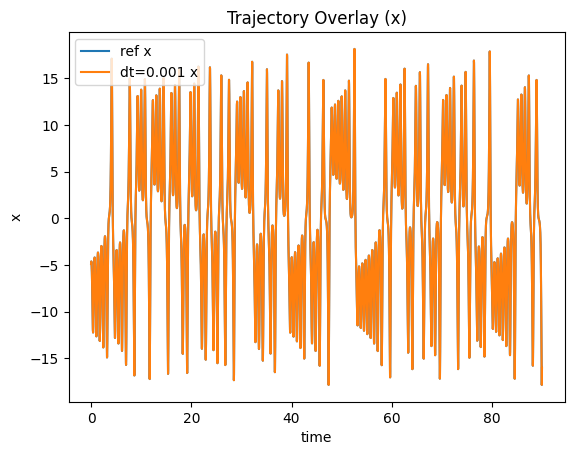

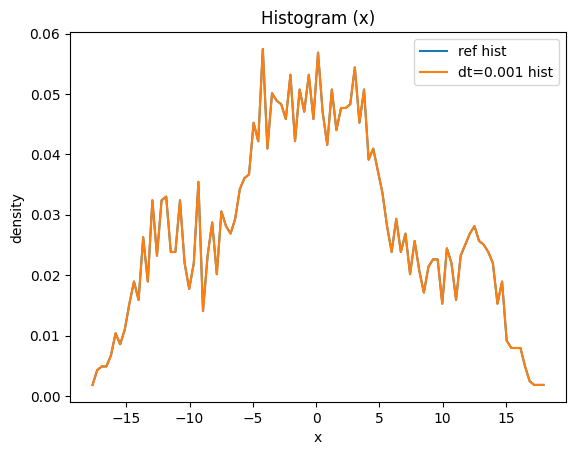

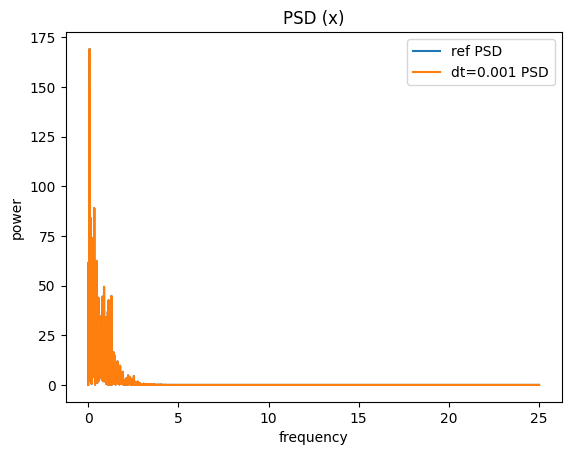

In [25]:

def make_plots_for_dt(dt):
    # build reference / candidate observed sequences
    X_ref = integrate_lorenz63(X0, DT_REF, TOTAL_TIME, WARMUP_TIME)
    REF_obs = downsample_to_dt_obs(X_ref, DT_REF, DT_OBS)

    X = integrate_lorenz63(X0, dt, TOTAL_TIME, WARMUP_TIME)
    X_obs = downsample_to_dt_obs(X, dt, DT_OBS)

    n = min(len(X_obs), len(REF_obs))
    X_obs = X_obs[:n]
    REF_obs = REF_obs[:n]

    t = np.arange(n) * DT_OBS

    # Trajectory overlay (x coordinate)
    plt.figure()
    plt.plot(t, REF_obs[:,0], label="ref x")
    plt.plot(t, X_obs[:,0], label=f"dt={dt} x")
    plt.xlabel("time")
    plt.ylabel("x")
    plt.legend()
    plt.title("Trajectory Overlay (x)")
    plt.show()

    # Histograms (x)
    xmin = min(REF_obs[:,0].min(), X_obs[:,0].min())
    xmax = max(REF_obs[:,0].max(), X_obs[:,0].max())
    edges = np.linspace(xmin, xmax, 100)
    href, _ = np.histogram(REF_obs[:,0], bins=edges, density=True)
    hcmp, _ = np.histogram(X_obs[:,0],  bins=edges, density=True)

    centers = 0.5*(edges[:-1] + edges[1:])
    plt.figure()
    plt.plot(centers, href, label="ref hist")
    plt.plot(centers, hcmp, label=f"dt={dt} hist")
    plt.xlabel("x")
    plt.ylabel("density")
    plt.legend()
    plt.title("Histogram (x)")
    plt.show()

    # PSD (x)
    def psd_1d(x, dt):
        x = x - np.mean(x)
        n = len(x)
        freqs = np.fft.rfftfreq(n, d=dt)
        X = np.fft.rfft(x)
        psd = (np.abs(X)**2) / (n / dt)
        return freqs, psd

    f_ref, P_ref = psd_1d(REF_obs[:,0], DT_OBS)
    f_cmp, P_cmp = psd_1d(X_obs[:,0], DT_OBS)

    plt.figure()
    plt.plot(f_ref, P_ref, label="ref PSD")
    plt.plot(f_cmp, P_cmp, label=f"dt={dt} PSD")
    plt.xlabel("frequency")
    plt.ylabel("power")
    plt.legend()
    plt.title("PSD (x)")
    plt.show()

# Example usage (uncomment to plot for the selected best dt):
if best is not None:
    make_plots_for_dt(best['dt'])



### Notes
- Increase `TOTAL_TIME` for more stable distributional/spectral estimates.
- If **no** candidate passes, try smaller steps or relax thresholds slightly; if **many** pass, consider tightening thresholds.
- For dataset creation, you can still save observations at `DT_OBS` by downsampling the high‑resolution integration.
- The Lyapunov estimate here uses a simple two‑trajectory method; for research‑grade estimates, consider a more sophisticated algorithm.
